In [1]:
from astropy.io import fits
import pandas as pd
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt

from GalVel_Pop import gal_population, UVW

In [2]:
gaia_for_galah_dat = Table.read('galah_dr4_vac_wise_tmass_gaiadr3_240705.fits', format='fits')
names_gaia_for_galah = [name for name in gaia_for_galah_dat.colnames if len(gaia_for_galah_dat[name].shape) <= 1]
gaia_for_galah_df = gaia_for_galah_dat[names_gaia_for_galah].to_pandas()

In [3]:
gaia_for_galah_df_columns = ['sobject_id', 
                             'ra', 'ra_error', 'dec', 'dec_error', 
                            'parallax', 'parallax_error',
                            'pmra', 'pmra_error', 
                            'pmdec', 'pmdec_error',
                            'phot_g_mean_mag',
                            'phot_bp_mean_mag', 'phot_rp_mean_mag',
                            'radial_velocity', 'radial_velocity_error',
                            'r_med_geo', 'r_med_photogeo',]

gaia_for_galah_df = gaia_for_galah_df[gaia_for_galah_df_columns]

In [4]:
galah_dat = Table.read('galah_dr4_allstar_240705.fits', format='fits')
names_galah = [name for name in galah_dat.colnames if len(galah_dat[name].shape) <= 1]
galah_df = galah_dat[names_galah].to_pandas()

In [5]:
gaia_df_columns = ['sobject_id', 'gaiadr3_source_id',
                    'rv_comp_1', 'e_rv_comp_1', 'rv_gaia_dr3', 'e_rv_gaia_dr3',
                    'snr_px_ccd2', 'flag_sp', 
                    'teff', 'e_teff',
                    'logg', 'e_logg', 
                    'fe_h', 'e_fe_h', 'flag_fe_h',
                    'c_fe', 'e_c_fe', 'flag_c_fe',
                    'o_fe', 'e_o_fe', 'flag_o_fe',
                    'mg_fe', 'e_mg_fe', 'flag_mg_fe',
                    'si_fe', 'e_si_fe', 'flag_si_fe',
]

galah_df = galah_df[gaia_df_columns]

### Excluding bad measurements based on some flags

In [6]:
criteria = (galah_df['snr_px_ccd2'] > 50) & (galah_df['teff'] > 4000) & (galah_df['teff'] < 6300) & (galah_df['flag_sp'] == 0) & (galah_df['logg'] > 1) & (galah_df['logg'] < 4.7)
galah_df = galah_df[criteria]
len(galah_df)

269611

In [7]:
def calculate_X_H(df, element):
    # Create column names dynamically
    X_FE_col = f'{element}_fe'
    X_FE_err_col = f'e_{element}_fe'
    FE_H_col = 'fe_h'
    FE_H_err_col = 'e_fe_h'
    
    # Compute X_H
    df[f'{element}_h'] = df[X_FE_col] + df[FE_H_col]
    
    # Propagate the uncertainties
    df[f'e_{element}_h'] = np.sqrt(df[X_FE_err_col]**2 + df[FE_H_err_col]**2)
    
    return df

galah_df = calculate_X_H(galah_df, 'c')
galah_df = calculate_X_H(galah_df, 'o')
galah_df = calculate_X_H(galah_df, 'mg')
galah_df = calculate_X_H(galah_df, 'si')

In [8]:
abundance_criteria = (
    (galah_df['flag_fe_h'] == 0) &
    (galah_df['fe_h'] > -1) & 
    (galah_df['fe_h'] < 0.6) & 
    (galah_df['e_fe_h'] < 0.1) &
    (galah_df['flag_mg_fe'] == 0) &
    (galah_df['mg_h'] > -1) & 
    (galah_df['mg_h'] < 0.6) & 
    (galah_df['e_mg_h'] < 0.1) &
    (galah_df['flag_si_fe'] == 0) &
    (galah_df['si_h'] > -1) & 
    (galah_df['si_h'] < 0.6) & 
    (galah_df['e_si_h'] < 0.1) &
    (galah_df['flag_o_fe'] == 0) &
    (galah_df['o_h'] > -1) & 
    (galah_df['o_h'] < 0.6) & 
    (galah_df['e_o_h'] < 0.1) 
)
galah_df = galah_df[abundance_criteria]
print (f' Galah sample with good spectra and not too coold/hot: {len(galah_df)} stars')

 Galah sample with good spectra and not too coold/hot: 203462 stars


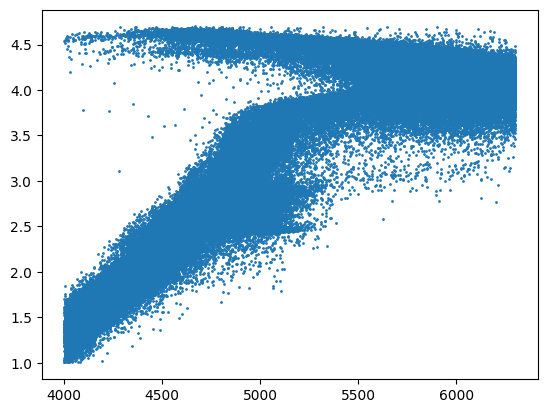

In [9]:
plt.scatter(galah_df.teff, galah_df.logg, s = 1)

In [10]:
galah_sample_dwarfs = galah_df[(galah_df['logg'] > 4.1)  & (galah_df['teff'] > 5000)]
print (f'{len(galah_sample_dwarfs)} dwarf stars')

72299 dwarf stars


In [11]:
galah_sample_giants = galah_df[(galah_df['logg'] < 2.5) & (galah_df['teff'] < 5000)]
print (f'{len(galah_sample_giants)} giant stars')

43753 giant stars


In [12]:
galah_final_sample = pd.merge(galah_sample_dwarfs, galah_sample_giants, how='outer')
print (f'{len(galah_final_sample)} total stars')

116052 total stars


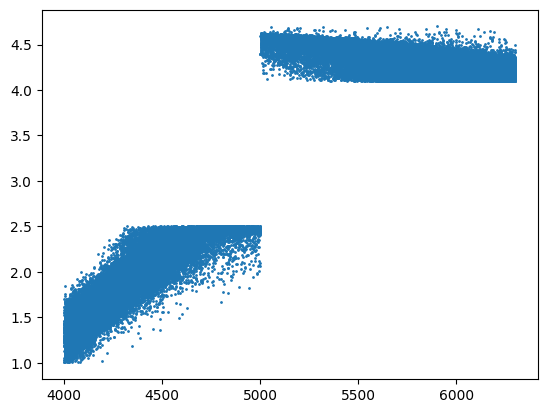

In [13]:
plt.scatter(galah_final_sample.teff, galah_final_sample.logg, s = 1)

In [14]:
galah_final_sample_kin = pd.merge(galah_final_sample, gaia_for_galah_df, on = 'sobject_id', how='inner')
print (f'{len(galah_final_sample_kin)} total stars with kinematics')

116052 total stars with kinematics


In [15]:
kinematic_criteria = (
    (galah_final_sample_kin['parallax'] == galah_final_sample_kin['parallax']) &
    (galah_final_sample_kin['pmra'] == galah_final_sample_kin['pmra']) &
    (galah_final_sample_kin['pmdec'] == galah_final_sample_kin['pmdec'])
)

galah_final_sample_kin = galah_final_sample_kin[kinematic_criteria]
print (f' Galah sample with good kinematics: {len(galah_final_sample_kin)} stars')

 Galah sample with good kinematics: 116050 stars


In [16]:
def calculate_uvw(row):
    UVW_lsr =  UVW(row['ra'], row['dec'], row['pmra'], row['pmdec'], row['rv_comp_1'], row['parallax'])
    return UVW_lsr[0], UVW_lsr[1], UVW_lsr[2] 

# Apply the function to each row using apply with axis=1
galah_final_sample_kin['U_lsr'], galah_final_sample_kin['V_lsr'], galah_final_sample_kin['W_lsr'] = zip(*galah_final_sample_kin.apply(calculate_uvw, axis=1))

In [17]:
# Define a function to apply gal_population to each row
def calculate_probabilities(row):
    probs =  gal_population(row['U_lsr'], row['V_lsr'], row['W_lsr'], char_vel='Mean')
    return probs[0]

# Apply the function to each row using apply with axis=1
galah_final_sample_kin['P_gal'] = galah_final_sample_kin.apply(calculate_probabilities, axis=1)

c:\Users\adbva\IA\Students\PhD\Barbara_soares\m_dwarfs\samples\GalVel_Pop.py:160: RuntimeWarning: invalid value encountered in double_scalars
  Prob[key] = np.round(100 * abs_p[i] / np.sum(abs_p), 1)


In [24]:
# Removing unnesseery columns
galah_final_sample_kin = galah_final_sample_kin.drop(['rv_gaia_dr3', 'e_rv_gaia_dr3', 'snr_px_ccd2', 'flag_sp',
                                                      'flag_fe_h', 'flag_o_fe', 'flag_mg_fe', 'flag_si_fe',
                                                      'ra_error', 'dec_error',  'radial_velocity', 'radial_velocity_error',],axis = 1)

In [28]:
def rounding_to_decimals(df, cols, dec):
    for col in cols:
        df[col] = df[col].apply(lambda x: round(x, dec))
    return df

# Example usage with a list of columns
columns_to_round_to_2_decimals = [
    'rv_comp_1', 'e_rv_comp_1', 'logg', 'e_logg', 'fe_h', 'e_fe_h', 'c_fe', 'e_c_fe', 'o_fe',
    'e_o_fe', 'mg_fe', 'e_mg_fe', 'si_fe', 'e_si_fe', 'c_h', 'e_c_h', 'o_h',
    'e_o_h', 'mg_h', 'e_mg_h', 'si_h', 'e_si_h', 'parallax',
    'parallax_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error',
    'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag', 'r_med_geo',
    'r_med_photogeo', 'U_lsr', 'V_lsr', 'W_lsr',
    ]

columns_to_round_to_0_decimals = ['teff', 'e_teff',]

galah_final_sample_kin = rounding_to_decimals(galah_final_sample_kin, columns_to_round_to_2_decimals, 2)
galah_final_sample_kin = rounding_to_decimals(galah_final_sample_kin, columns_to_round_to_0_decimals, 0)


In [29]:
galah_final_sample_kin.to_csv('galahDR4_final_sample.csv')

### Selecting best C measurements

In [30]:
carbon_criteria = (
    (galah_final_sample_kin['flag_c_fe'] == 0) &
    (galah_final_sample_kin['c_h'] > -1) & 
    (galah_final_sample_kin['c_h'] < 0.6) & 
    (galah_final_sample_kin['e_c_h'] < 0.1) 
)
galah_final_sample_kin_carbon = galah_final_sample_kin[carbon_criteria]
galah_final_sample_kin_carbon.drop(['flag_c_fe'], axis = 1, inplace = True)
print (f' Galah sample with good carbon abundances: {len(galah_final_sample_kin_carbon)} stars')


KeyError: 'flag_c_fe'

In [20]:
galah_final_sample_kin_carbon.to_csv('galahDR4_final_carbon_sample.csv')